# 1 Повнозв'язані нейронні мережі

In [137]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, accuracy_score

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"PyTorch використовує пристрій: {device}")

PyTorch використовує пристрій: cuda


In [138]:
from imblearn.over_sampling import SMOTE
from torch.utils.data import DataLoader, TensorDataset
import torch

# 1. Завантаження та розбиття (як було)
df = pd.read_csv('cleaned_sensor_data.csv')
target_col = 'Pass/Fail'
X = df.drop(columns=[target_col]).values
y = df[target_col].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Масштабування
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. МАГІЯ SMOTE: Генеруємо штучні одиниці ТІЛЬКИ для тренувальної вибірки
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

print(f"Було даних до SMOTE: {len(y_train)}, стало після: {len(y_train_smote)}")

# 4. Перетворення у тензори (зверни увагу, беремо дані зі SMOTE)
X_train_tensor = torch.FloatTensor(X_train_smote)
y_train_tensor = torch.FloatTensor(y_train_smote).view(-1, 1)
X_test_tensor = torch.FloatTensor(X_test_scaled)
y_test_tensor = torch.FloatTensor(y_test).view(-1, 1)

# 5. DataLoader
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True) # Зменшили батч

test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

Було даних до SMOTE: 1253, стало після: 2346


In [139]:
class VerySimpleMLP(nn.Module):
    def __init__(self, input_size):
        super(VerySimpleMLP, self).__init__()
        self.network = nn.Sequential(
# Перший прихований шар (64 нейрони)
            nn.Linear(input_size, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Dropout(0.5),


            # Третій прихований шар (16 нейронів)
            nn.Linear(32, 16),
            nn.BatchNorm1d(16),
            nn.ReLU(),
            nn.Dropout(0.4),

            # Вихідний шар (на вхід приймає 16, видає 1 для бінарної класифікації)
            nn.Linear(16, 1)
        )

    def forward(self, x):
        return self.network(x)

input_dim = X_train_scaled.shape[1]
model = VerySimpleMLP(input_dim).to(device)

# Звичайна функція втрат (бо SMOTE вже все збалансував)
criterion = nn.BCEWithLogitsLoss()
# Сильна L2 регуляризація
optimizer = optim.Adam(model.parameters(), lr=0.0001, weight_decay=1e-2)
epochs = 7 # Більше не треба

In [140]:
import copy

criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=0.0001, weight_decay=1e-3)
epochs = 100

train_losses = []
val_losses = []

# --- Змінні для збереження найкращої моделі ---
best_val_loss = float('inf')
best_epoch = 0
best_model_weights = copy.deepcopy(model.state_dict())

# Цикл навчання
for epoch in range(epochs):
    model.train() # Режим тренування
    running_loss = 0.0

    for batch_X, batch_y in train_loader:
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)

        optimizer.zero_grad() # Обнуляємо градієнти
        outputs = model(batch_X) # Прямий прохід
        loss = criterion(outputs, batch_y) # Рахуємо помилку
        loss.backward() # Зворотний прохід
        optimizer.step() # Оновлюємо ваги

        running_loss += loss.item()

    avg_train_loss = running_loss / len(train_loader)
    train_losses.append(avg_train_loss)

    # Режим валідації (оцінка на тестових даних без зміни ваг)
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for batch_X, batch_y in test_loader:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)
            outputs = model(batch_X)
            loss = criterion(outputs, batch_y)
            val_loss += loss.item()

    avg_val_loss = val_loss / len(test_loader)
    val_losses.append(avg_val_loss)

    # --- ПЕРЕВІРКА НА НАЙКРАЩУ ЕПОХУ ---
    # Якщо поточна помилка менша за попередню найкращу — зберігаємо ваги
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        best_epoch = epoch + 1 # +1, бо епохи рахуються з 0
        best_model_weights = copy.deepcopy(model.state_dict())

    # Виводимо прогрес кожні 10 епох
    if (epoch + 1) % 10 == 0:
        print(f'Епоха [{epoch+1}/{epochs}] | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f}')

print("\n--- Навчання завершено ---")
print(f"Ідеальна кількість епох (найменша помилка на валідації): {best_epoch}")

# Відкат моделі до ідеального стану перед фінальним тестуванням
model.load_state_dict(best_model_weights)
print("Найкращі ваги успішно завантажено в модель!")

Епоха [10/100] | Train Loss: 0.4942 | Val Loss: 0.5189
Епоха [20/100] | Train Loss: 0.3471 | Val Loss: 0.4061
Епоха [30/100] | Train Loss: 0.2384 | Val Loss: 0.3354
Епоха [40/100] | Train Loss: 0.1700 | Val Loss: 0.3078
Епоха [50/100] | Train Loss: 0.1390 | Val Loss: 0.3178
Епоха [60/100] | Train Loss: 0.1167 | Val Loss: 0.3366
Епоха [70/100] | Train Loss: 0.0966 | Val Loss: 0.3497
Епоха [80/100] | Train Loss: 0.0836 | Val Loss: 0.3777
Епоха [90/100] | Train Loss: 0.0707 | Val Loss: 0.3934
Епоха [100/100] | Train Loss: 0.0721 | Val Loss: 0.4293

--- Навчання завершено ---
Ідеальна кількість епох (найменша помилка на валідації): 42
Найкращі ваги успішно завантажено в модель!


Візуалізація Learning Curves

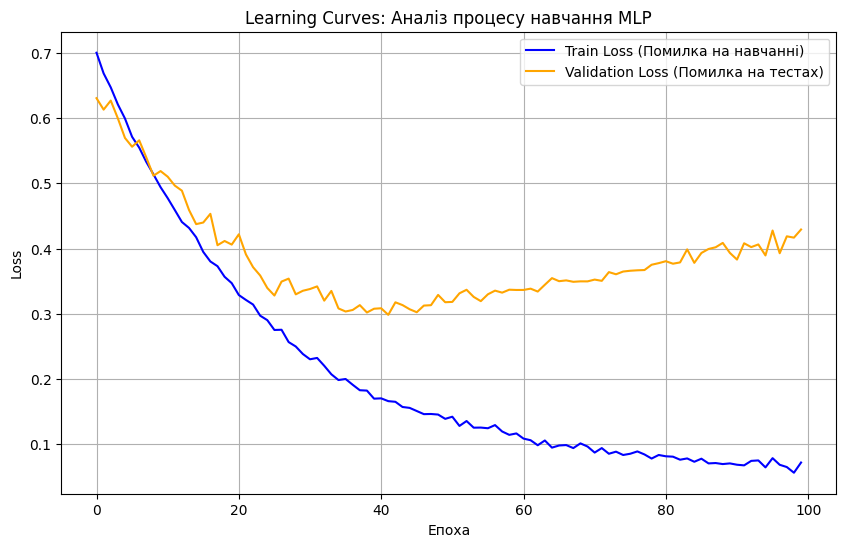

In [141]:
plt.figure(figsize=(10, 6))
plt.plot(train_losses, label='Train Loss (Помилка на навчанні)', color='blue')
plt.plot(val_losses, label='Validation Loss (Помилка на тестах)', color='orange')
plt.title('Learning Curves: Аналіз процесу навчання MLP')
plt.xlabel('Епоха')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

Оцінка якості

In [142]:
model.eval()
y_pred_list = []
y_true_list = []

with torch.no_grad():
    for batch_X, batch_y in test_loader:
        batch_X = batch_X.to(device)
        outputs = model(batch_X)
        # Оскільки на виході логіти, пропускаємо через сигмоїду і округлюємо (0 або 1)
        predicted = (torch.sigmoid(outputs) > 0.3).float()
        y_pred_list.extend(predicted.cpu().numpy())
        y_true_list.extend(batch_y.numpy())

print("\n--- Фінальні результати нейромережі (MLP) ---")
print(f"Accuracy: {accuracy_score(y_true_list, y_pred_list):.4f}")
print("Classification Report:")
print(classification_report(y_true_list, y_pred_list))


--- Фінальні результати нейромережі (MLP) ---
Accuracy: 0.8439
Classification Report:
              precision    recall  f1-score   support

         0.0       0.94      0.89      0.91       290
         1.0       0.18      0.29      0.22        24

    accuracy                           0.84       314
   macro avg       0.56      0.59      0.57       314
weighted avg       0.88      0.84      0.86       314



# 2 Згорткові нейронні мережі

In [145]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torchvision import datasets, models, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np
import copy
import time

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch використовує: {device}")

# Стандартні трансформації (ресайз до 150x150, як в оригіналі)
data_transforms = {
    'train': transforms.Compose([
        transforms.Resize((150, 150)),
        transforms.RandomHorizontalFlip(), # Легка аугментація
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'val': transforms.Compose([
        transforms.Resize((150, 150)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
}

data_dir = 'dataset'
# Шляхи до папок, які ми щойно розпакували
image_datasets = {
    'train': datasets.ImageFolder(f'seg_train/seg_train', data_transforms['train']),
    'val': datasets.ImageFolder(f'seg_test/seg_test', data_transforms['val'])
}

dataloaders = {x: DataLoader(image_datasets[x], batch_size=64, shuffle=True) for x in ['train', 'val']}
class_names = image_datasets['train'].classes
print(f"Знайдено класи: {class_names}")

PyTorch використовує: cuda
Знайдено класи: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


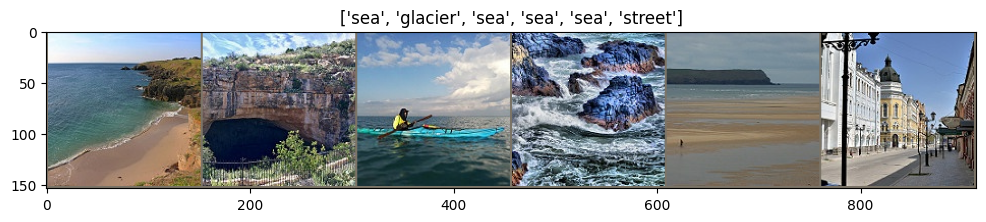

In [146]:
def imshow(inp, title=None):
    inp = inp.numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    inp = std * inp + mean
    inp = np.clip(inp, 0, 1) # Відсікаємо зайве для правильного відображення

    plt.figure(figsize=(12, 6))
    plt.imshow(inp)
    if title is not None:
        plt.title(title)
    plt.pause(0.001)

# Беремо один батч і показуємо перші 6 картинок
inputs, classes = next(iter(dataloaders['train']))
out = torchvision.utils.make_grid(inputs[:6])
imshow(out, title=[class_names[x] for x in classes[:6]])

In [159]:
def train_model(model, criterion, optimizer, num_epochs=10):
    since = time.time()
    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0

    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

    for epoch in range(num_epochs):
        print(f'Епоха {epoch+1}/{num_epochs}')
        print('-' * 10)

        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()
            else:
                model.eval()

            running_loss = 0.0
            running_corrects = 0

            for inputs, labels in dataloaders[phase]:
                inputs = inputs.to(device)
                labels = labels.to(device)

                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)

            # --- ГОЛОВНЕ ВИПРАВЛЕННЯ ---
            # Тепер ми ділимо на правильну кількість текстів, а не на 25 тисяч картинок
            dataset_size = len(dataloaders[phase].dataset)
            epoch_loss = running_loss / dataset_size
            epoch_acc = running_corrects.double() / dataset_size

            history[f'{phase}_loss'].append(epoch_loss)
            history[f'{phase}_acc'].append(epoch_acc.item())

            print(f'{phase.capitalize()} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')

            if phase == 'val' and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_model_wts = copy.deepcopy(model.state_dict())

        print()

    time_elapsed = time.time() - since
    print(f'Навчання завершено за {time_elapsed // 60:.0f}хв {time_elapsed % 60:.0f}с')
    print(f'Найкраща Validation Accuracy: {best_acc:4f}')

    model.load_state_dict(best_model_wts)
    return model, history

In [149]:
class CustomCNN(nn.Module):
    def __init__(self, num_classes):
        super(CustomCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            # Адаптивний пул гарантує фіксований розмір виходу незалежно від вхідної картинки
            nn.AdaptiveAvgPool2d((5, 5))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 5 * 5, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

custom_model = CustomCNN(len(class_names)).to(device)
criterion = nn.CrossEntropyLoss()
optimizer_custom = optim.Adam(custom_model.parameters(), lr=0.001)

# Запускаємо навчання на 10 епох
print("--- Навчання Власної CNN ---")
custom_model, custom_history = train_model(custom_model, criterion, optimizer_custom, num_epochs=10)

--- Навчання Власної CNN ---
Епоха 1/10
----------
Train Loss: 1.0289 Acc: 0.5973
Val Loss: 0.7947 Acc: 0.7063

Епоха 2/10
----------
Train Loss: 0.7564 Acc: 0.7191
Val Loss: 0.6530 Acc: 0.7533

Епоха 3/10
----------
Train Loss: 0.6457 Acc: 0.7674
Val Loss: 0.5785 Acc: 0.7977

Епоха 4/10
----------
Train Loss: 0.5811 Acc: 0.7922
Val Loss: 0.5247 Acc: 0.8190

Епоха 5/10
----------
Train Loss: 0.5233 Acc: 0.8132
Val Loss: 0.5039 Acc: 0.8267

Епоха 6/10
----------
Train Loss: 0.5012 Acc: 0.8225
Val Loss: 0.4911 Acc: 0.8303

Епоха 7/10
----------
Train Loss: 0.4796 Acc: 0.8266
Val Loss: 0.4467 Acc: 0.8423

Епоха 8/10
----------
Train Loss: 0.4495 Acc: 0.8417
Val Loss: 0.4389 Acc: 0.8530

Епоха 9/10
----------
Train Loss: 0.4346 Acc: 0.8461
Val Loss: 0.4274 Acc: 0.8553

Епоха 10/10
----------
Train Loss: 0.4146 Acc: 0.8505
Val Loss: 0.4716 Acc: 0.8413

Навчання завершено за 5хв 31с
Найкраща Validation Accuracy: 0.855333


In [150]:
# Завантажуємо навчену ResNet18
resnet_model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Замінюємо останній шар (Fully Connected) під нашу кількість класів
num_ftrs = resnet_model.fc.in_features
resnet_model.fc = nn.Linear(num_ftrs, len(class_names))

resnet_model = resnet_model.to(device)
# Зменшуємо Learning Rate, бо мережа ВЖЕ навчена, їй треба лише "дошліфувати" знання
optimizer_resnet = optim.Adam(resnet_model.parameters(), lr=0.0001)

print("--- Навчання Pretrained ResNet18 ---")
resnet_model, resnet_history = train_model(resnet_model, criterion, optimizer_resnet, num_epochs=10)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 196MB/s]


--- Навчання Pretrained ResNet18 ---
Епоха 1/10
----------
Train Loss: 0.3007 Acc: 0.8958
Val Loss: 0.1883 Acc: 0.9327

Епоха 2/10
----------
Train Loss: 0.1381 Acc: 0.9520
Val Loss: 0.1825 Acc: 0.9380

Епоха 3/10
----------
Train Loss: 0.0853 Acc: 0.9703
Val Loss: 0.2090 Acc: 0.9320

Епоха 4/10
----------
Train Loss: 0.0626 Acc: 0.9797
Val Loss: 0.2096 Acc: 0.9373

Епоха 5/10
----------
Train Loss: 0.0397 Acc: 0.9879
Val Loss: 0.2924 Acc: 0.9220

Епоха 6/10
----------
Train Loss: 0.0378 Acc: 0.9875
Val Loss: 0.2528 Acc: 0.9337

Епоха 7/10
----------
Train Loss: 0.0219 Acc: 0.9929
Val Loss: 0.2989 Acc: 0.9300

Епоха 8/10
----------
Train Loss: 0.0218 Acc: 0.9928
Val Loss: 0.2604 Acc: 0.9333

Епоха 9/10
----------
Train Loss: 0.0274 Acc: 0.9911
Val Loss: 0.3022 Acc: 0.9300

Епоха 10/10
----------
Train Loss: 0.0182 Acc: 0.9941
Val Loss: 0.3014 Acc: 0.9317

Навчання завершено за 7хв 27с
Найкраща Validation Accuracy: 0.938000


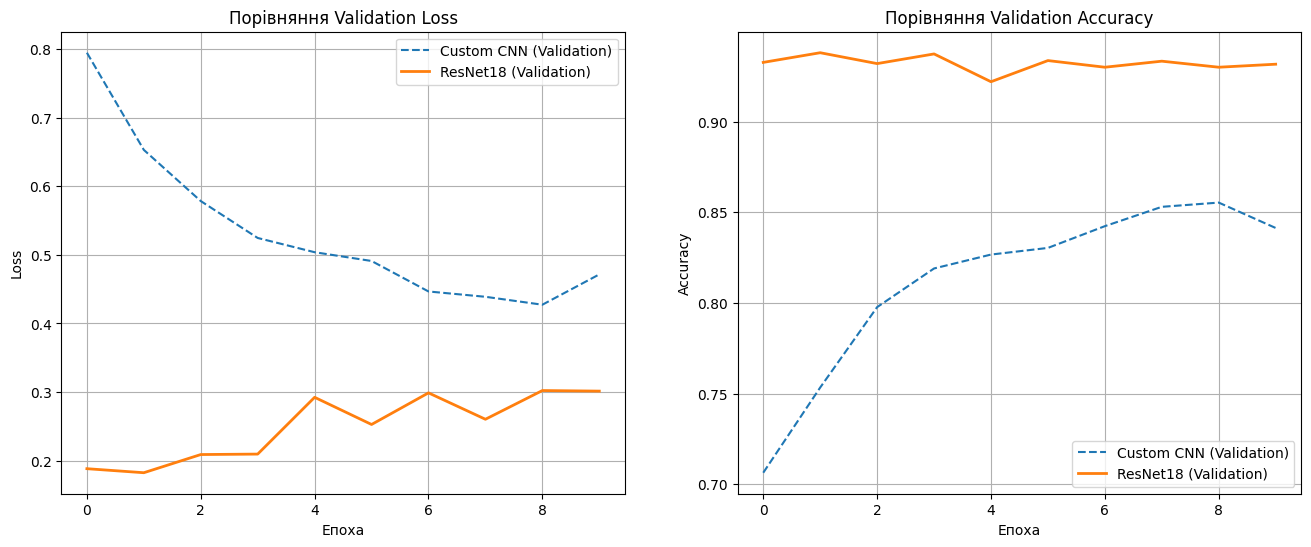

In [151]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Графік Loss (Помилка)
axes[0].plot(custom_history['val_loss'], label='Custom CNN (Validation)', linestyle='--')
axes[0].plot(resnet_history['val_loss'], label='ResNet18 (Validation)', linewidth=2)
axes[0].set_title('Порівняння Validation Loss')
axes[0].set_xlabel('Епоха')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True)

# Графік Accuracy (Точність)
axes[1].plot(custom_history['val_acc'], label='Custom CNN (Validation)', linestyle='--')
axes[1].plot(resnet_history['val_acc'], label='ResNet18 (Validation)', linewidth=2)
axes[1].set_title('Порівняння Validation Accuracy')
axes[1].set_xlabel('Епоха')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True)

plt.show()

# 3 Нейронні мережі для класифікації текстів

In [153]:
!pip install torchtext

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.2/64.2 kB 6.1 MB/s eta 0:00:00


In [160]:
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from collections import Counter
import re
import copy
import time
import torchtext

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Завантаження даних (переконайся, що назви колонок збігаються з твоїм файлом)
df = pd.read_csv('bbc-news-data.csv', sep='\t') # Зміни sep=',', якщо файл через кому
texts = df['content'].fillna('').astype(str).tolist()

# Перетворюємо текстові категорії на числа (0, 1, 2...)
df['category_code'] = df['category'].astype('category').cat.codes
labels = df['category_code'].tolist()
num_classes = len(set(labels))

# 2. Токенізація (чистимо від пунктуації, переводимо в нижній регістр)
def tokenize(text):
    return re.findall(r'\b\w+\b', text.lower())

tokenized_texts = [tokenize(text) for text in texts]

# 3. Побудова словника
vocab = Counter()
for text in tokenized_texts:
    vocab.update(text)

max_words = 10000
# <PAD> - заповнювач для коротких текстів, <UNK> - для невідомих слів
word2idx = {'<PAD>': 0, '<UNK>': 1}
for word, _ in vocab.most_common(max_words - 2):
    word2idx[word] = len(word2idx)

# 4. Перетворення в індекси та Padding до довжини 200
MAX_LEN = 200
def encode_and_pad(text_tokens):
    encoded = [word2idx.get(w, word2idx['<UNK>']) for w in text_tokens]
    if len(encoded) < MAX_LEN:
        encoded += [word2idx['<PAD>']] * (MAX_LEN - len(encoded))
    else:
        encoded = encoded[:MAX_LEN]
    return encoded

X = torch.tensor([encode_and_pad(t) for t in tokenized_texts])
y = torch.tensor(labels, dtype=torch.long)

# 5. Створення DataLoaders (80% Train / 20% Val)
dataset = TensorDataset(X, y)
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_dataset, val_dataset = torch.utils.data.random_split(dataset, [train_size, val_size])

dataloaders = {
    'train': DataLoader(train_dataset, batch_size=64, shuffle=True),
    'val': DataLoader(val_dataset, batch_size=64)
}
print(f"Словник створено: {len(word2idx)} слів. Класів: {num_classes}")

Словник створено: 10000 слів. Класів: 5


In [161]:
class TextLSTM(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, num_classes, pretrained_embeddings=None):
        super(TextLSTM, self).__init__()

        # Шар Embedding перетворює індекси слів на вектори
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)

        # Якщо передали готові ваги GloVe - завантажуємо їх
        if pretrained_embeddings is not None:
            self.embedding.weight.data.copy_(pretrained_embeddings)

        # Двонаправлена LSTM (читає текст і зліва направо, і справа наліво)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, num_layers=2,
                            batch_first=True, bidirectional=True, dropout=0.3)

        self.fc = nn.Sequential(
            nn.Dropout(0.5),
            nn.Linear(hidden_dim * 2, num_classes) # *2, бо bidirectional
        )

    def forward(self, text):
        embedded = self.embedding(text)
        # Вихід LSTM та останні приховані стани
        lstm_out, (hidden, cell) = self.lstm(embedded)
        # Зклеюємо стани з прямого та зворотного проходу останнього шару
        hidden_concat = torch.cat((hidden[-2,:,:], hidden[-1,:,:]), dim=1)
        out = self.fc(hidden_concat)
        return out

In [162]:
embed_dim = 100
hidden_dim = 128

model_random = TextLSTM(len(word2idx), embed_dim, hidden_dim, num_classes).to(device)
criterion = nn.CrossEntropyLoss()
optimizer_random = optim.Adam(model_random.parameters(), lr=0.001)

print("--- Навчання LSTM (Випадкові ваги) ---")
# ВИКОРИСТАЙ функцію train_model з Завдання 2 (попередня лаба),
# передавши їй model_random. Вона ідеально підійде і сюди.
model_random, history_random = train_model(model_random, criterion, optimizer_random, num_epochs=10)

--- Навчання LSTM (Випадкові ваги) ---
Епоха 1/10
----------
Train Loss: 1.5814 Acc: 0.3011
Val Loss: 1.5463 Acc: 0.3146

Епоха 2/10
----------
Train Loss: 1.3410 Acc: 0.4601
Val Loss: 1.1816 Acc: 0.5618

Епоха 3/10
----------
Train Loss: 0.9822 Acc: 0.6225
Val Loss: 0.9737 Acc: 0.6090

Епоха 4/10
----------
Train Loss: 0.5935 Acc: 0.7927
Val Loss: 0.8196 Acc: 0.6876

Епоха 5/10
----------
Train Loss: 0.3764 Acc: 0.8713
Val Loss: 0.7551 Acc: 0.7371

Епоха 6/10
----------
Train Loss: 0.2213 Acc: 0.9303
Val Loss: 0.6861 Acc: 0.7775

Епоха 7/10
----------
Train Loss: 0.1435 Acc: 0.9607
Val Loss: 0.6300 Acc: 0.7910

Епоха 8/10
----------
Train Loss: 0.0742 Acc: 0.9809
Val Loss: 0.6645 Acc: 0.8022

Епоха 9/10
----------
Train Loss: 0.0698 Acc: 0.9815
Val Loss: 0.6354 Acc: 0.8135

Епоха 10/10
----------
Train Loss: 0.0422 Acc: 0.9904
Val Loss: 0.6784 Acc: 0.8067

Навчання завершено за 0хв 9с
Найкраща Validation Accuracy: 0.813483


In [165]:
print("Завантаження GloVe (може зайняти пару хвилин)...")
# Завантажуємо вектори розмірністю 100
glove = torchtext.vocab.GloVe(name='6B', dim=100)

# Створюємо матрицю для нашого словника
embedding_matrix = torch.zeros((len(word2idx), 100))
for word, idx in word2idx.items():
    if word in glove.stoi:
        embedding_matrix[idx] = glove.vectors[glove.stoi[word]]
    else:
        # Якщо слова немає в GloVe (наприклад, специфічне ім'я), даємо випадковий вектор
        embedding_matrix[idx] = torch.randn(100)

print("GloVe словник інтегровано!")

# Створюємо модель і передаємо їй матрицю GloVe
model_glove = TextLSTM(len(word2idx), embed_dim, hidden_dim, num_classes,
                       pretrained_embeddings=embedding_matrix).to(device)

# Можна поставити менший learning rate, бо база вже закладена
optimizer_glove = optim.Adam(model_glove.parameters(), lr=0.0005)

print("--- Навчання LSTM (GloVe Embeddings) ---")
model_glove, history_glove = train_model(model_glove, criterion, optimizer_glove, num_epochs=10)

Завантаження GloVe (може зайняти пару хвилин)...
GloVe словник інтегровано!
--- Навчання LSTM (GloVe Embeddings) ---
Епоха 1/10
----------
Train Loss: 1.5269 Acc: 0.3713
Val Loss: 1.2951 Acc: 0.4876

Епоха 2/10
----------
Train Loss: 0.8453 Acc: 0.6860
Val Loss: 0.6315 Acc: 0.7775

Епоха 3/10
----------
Train Loss: 0.4505 Acc: 0.8461
Val Loss: 0.3101 Acc: 0.9011

Епоха 4/10
----------
Train Loss: 0.2451 Acc: 0.9219
Val Loss: 0.3161 Acc: 0.9101

Епоха 5/10
----------
Train Loss: 0.2574 Acc: 0.9225
Val Loss: 0.2370 Acc: 0.9303

Епоха 6/10
----------
Train Loss: 0.2171 Acc: 0.9331
Val Loss: 0.5234 Acc: 0.8472

Епоха 7/10
----------
Train Loss: 0.2645 Acc: 0.9169
Val Loss: 0.1697 Acc: 0.9461

Епоха 8/10
----------
Train Loss: 0.1395 Acc: 0.9601
Val Loss: 0.2459 Acc: 0.9191

Епоха 9/10
----------
Train Loss: 0.0958 Acc: 0.9758
Val Loss: 0.1756 Acc: 0.9506

Епоха 10/10
----------
Train Loss: 0.0646 Acc: 0.9843
Val Loss: 0.1344 Acc: 0.9663

Навчання завершено за 0хв 9с
Найкраща Validation Acc

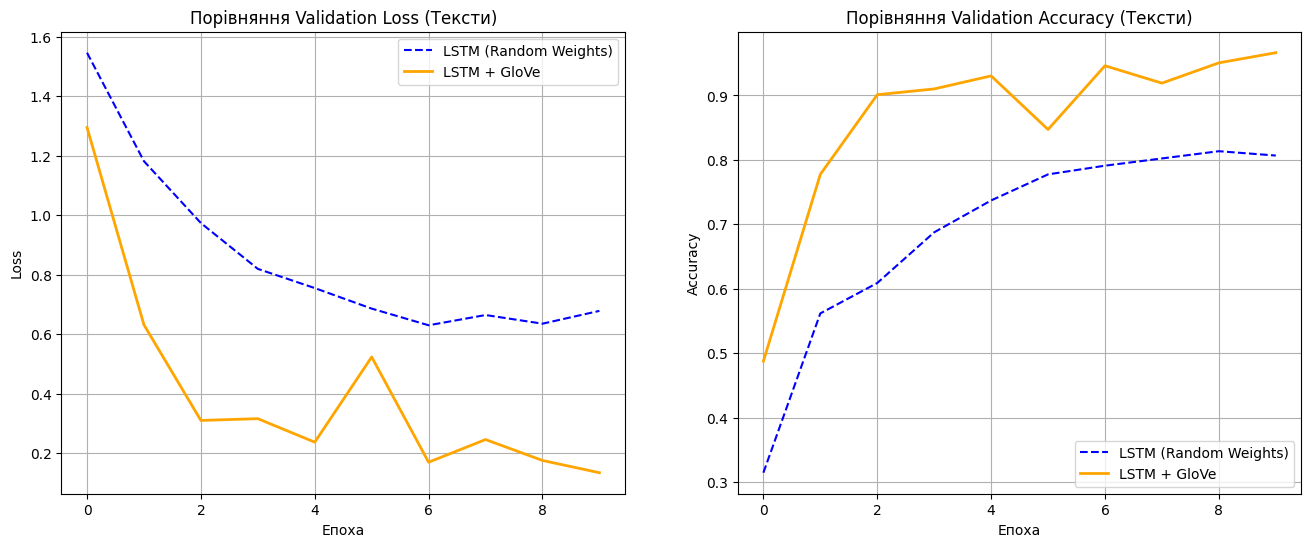

In [166]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Графік Loss (Помилка на валідації)
axes[0].plot(history_random['val_loss'], label='LSTM (Random Weights)', linestyle='--', color='blue')
axes[0].plot(history_glove['val_loss'], label='LSTM + GloVe', linewidth=2, color='orange')
axes[0].set_title('Порівняння Validation Loss (Тексти)')
axes[0].set_xlabel('Епоха')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True)

# Графік Accuracy (Точність на валідації)
axes[1].plot(history_random['val_acc'], label='LSTM (Random Weights)', linestyle='--', color='blue')
axes[1].plot(history_glove['val_acc'], label='LSTM + GloVe', linewidth=2, color='orange')
axes[1].set_title('Порівняння Validation Accuracy (Тексти)')
axes[1].set_xlabel('Епоха')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True)

plt.show()